In [11]:

import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Locate the project root from this notebook's working directory
project_root = Path.cwd()

# Walk upward until we find the project root
while not (project_root / "data" / "processed").is_dir():
    if project_root.parent == project_root:
        raise FileNotFoundError("Could not locate the project root.")
    project_root = project_root.parent

parquet_path = project_root / "data" / "processed" / "fact_trips_clean.parquet"

if not parquet_path.is_file():
    raise FileNotFoundError(
        f"Cleaned Parquet file not found: {parquet_path}\n"
        "Run the ETL pipeline first if the file has not been generated."
    )

df = pl.read_parquet(parquet_path)

print(f"Successfully loaded {len(df):,} cleaned rows.")


Successfully loaded 20,545,565 cleaned rows.


In [7]:
# Calculate the percentage of Unknown genders and Null ages per user type
reliability_stats = (
    df.group_by("user_type")
    .agg([
        pl.len().alias("total_trips"),
        (pl.col("gender") == "Unknown").sum().alias("unknown_gender_count"),
        pl.col("age").is_null().sum().alias("null_age_count")
    ])
    .with_columns([
        (pl.col("unknown_gender_count") / pl.col("total_trips") * 100).round(2).alias("pct_unknown_gender"),
        (pl.col("null_age_count") / pl.col("total_trips") * 100).round(2).alias("pct_null_age")
    ])
    .sort("user_type")
)

print("=== DATA RELIABILITY BY USER TYPE ===")
print(reliability_stats)

=== DATA RELIABILITY BY USER TYPE ===
shape: (2, 6)
┌────────────┬─────────────┬───────────────────┬────────────────┬───────────────────┬──────────────┐
│ user_type  ┆ total_trips ┆ unknown_gender_co ┆ null_age_count ┆ pct_unknown_gende ┆ pct_null_age │
│ ---        ┆ ---         ┆ unt               ┆ ---            ┆ r                 ┆ ---          │
│ str        ┆ u32         ┆ ---               ┆ u32            ┆ ---               ┆ f64          │
│            ┆             ┆ u32               ┆                ┆ f64               ┆              │
╞════════════╪═════════════╪═══════════════════╪════════════════╪═══════════════════╪══════════════╡
│ Customer   ┆ 2868398     ┆ 1238483           ┆ 306            ┆ 43.18             ┆ 0.01         │
│ Subscriber ┆ 17677167    ┆ 319506            ┆ 10853          ┆ 1.81              ┆ 0.06         │
└────────────┴─────────────┴───────────────────┴────────────────┴───────────────────┴──────────────┘


In [8]:
# Filter out Unknown genders and Null ages for a clean demographic comparison
clean_demo_df = df.filter(
    (pl.col("gender") != "Unknown") & 
    (pl.col("age").is_not_null())
)

demo_stats = (
    clean_demo_df.group_by(["user_type", "gender"])
    .agg([
        pl.len().alias("trip_count"),
        pl.col("age").mean().round(1).alias("avg_age"),
        pl.col("age").median().round(1).alias("median_age")
    ])
    .sort(["user_type", "gender"])
)

print("\n=== DEMOGRAPHIC DIFFERENCES (Valid Data Only) ===")
print(demo_stats)


=== DEMOGRAPHIC DIFFERENCES (Valid Data Only) ===
shape: (4, 5)
┌────────────┬────────┬────────────┬─────────┬────────────┐
│ user_type  ┆ gender ┆ trip_count ┆ avg_age ┆ median_age │
│ ---        ┆ ---    ┆ ---        ┆ ---     ┆ ---        │
│ str        ┆ str    ┆ u32        ┆ f64     ┆ f64        │
╞════════════╪════════╪════════════╪═════════╪════════════╡
│ Customer   ┆ Female ┆ 584713     ┆ 31.2    ┆ 29.0       │
│ Customer   ┆ Male   ┆ 1044987    ┆ 31.7    ┆ 29.0       │
│ Subscriber ┆ Female ┆ 4350882    ┆ 37.9    ┆ 34.0       │
│ Subscriber ┆ Male   ┆ 12997474   ┆ 38.8    ┆ 36.0       │
└────────────┴────────┴────────────┴─────────┴────────────┘


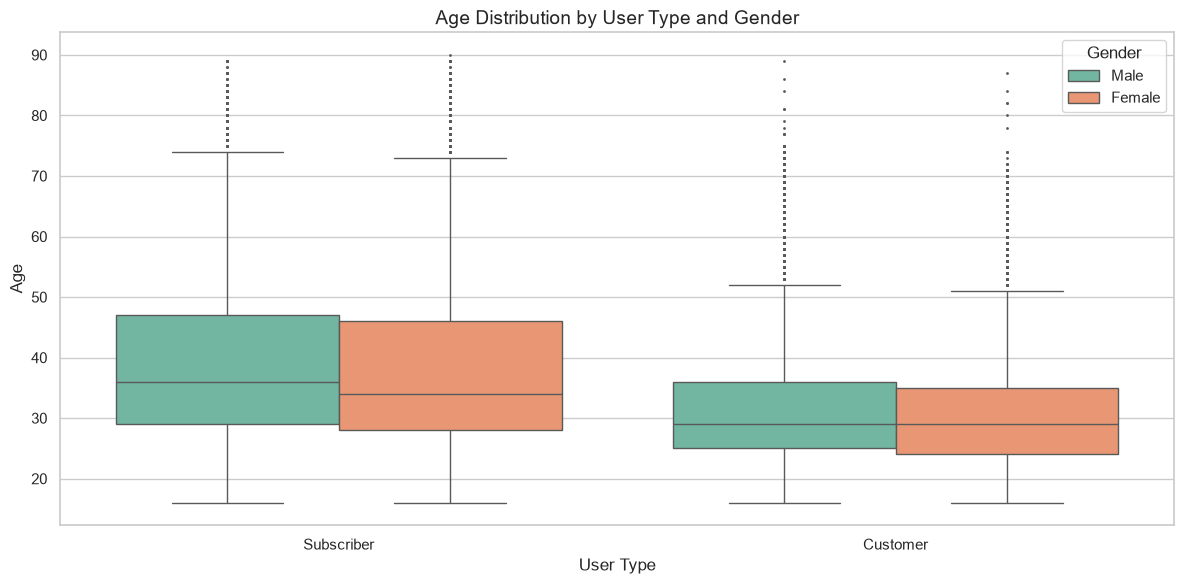

In [9]:
# Convert to pandas for seaborn (only for plotting, keeps memory low)
plot_df = clean_demo_df.sample(fraction=0.05, seed=42).to_pandas() # 5% sample is plenty for a clear distribution

plt.figure(figsize=(12, 6))
sns.boxplot(
    data=plot_df, 
    x="user_type", 
    y="age", 
    hue="gender",
    palette="Set2",
    fliersize=1 # Reduce outlier dot size for cleaner look
)

plt.title("Age Distribution by User Type and Gender", fontsize=14)
plt.xlabel("User Type", fontsize=12)
plt.ylabel("Age", fontsize=12)
plt.legend(title="Gender")
plt.tight_layout()
plt.show()

### Answer to Question 1

**1. How do user types differ with respect to Age and Gender?**
Based on the valid demographic data, there are clear distinctions between the two user types:
*   **Age:** Subscribers are notably older than Customers. The median age for Customers is **29 years old**, whereas the median age for Subscribers is **34–36 years old**. 
*   **Gender:** Both groups skew male, but the disparity is much larger among Subscribers. For Customers with known gender, the split is roughly 64% Male to 36% Female. For Subscribers, it is roughly 75% Male to 25% Female.

**2. Is the data equally reliable for both types?**
**No. The data is significantly more reliable for Subscribers.**
*   **Customers** have a massive **43.18% rate of "Unknown" gender**. This is expected behavior for short-term pass users, who typically rent bikes via quick kiosk transactions or mobile apps without creating a detailed user profile.
*   **Subscribers**, who must create an account and provide demographic details to purchase an annual membership, have a highly reliable gender capture rate (**only 1.81% unknown**). Age data is highly complete for both groups (< 0.1% nulls).

**Business Recommendation:** 
Any marketing analysis or persona profiling that relies on gender demographics should either be restricted to the **Subscriber** segment or explicitly call out the ~43% margin of error for the Customer segment. Conclusions drawn from Customer gender data will be heavily skewed toward the subset of short-term users who voluntarily provided that information.